# <h1 style="font-family: Trebuchet MS; padding: 20px; font-size: 25px; color: #F93822; text-align: center; line-height: 0.75;background-color: #ADD8E6"><b>Heart Failure Prediction</b><br></h1>

In [1]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/heart-failure-prediction/heart.csv


In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression , LinearRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler, QuantileTransformer, PowerTransformer, FunctionTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, roc_auc_score, roc_curve

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [3]:
df = pd.read_csv("/kaggle/input/heart-failure-prediction/heart.csv")

# <h1 style="font-family: Trebuchet MS; padding: 20px; font-size: 25px; color: #F93822; text-align: center; line-height: 0.75;background-color: #ADD8E6"><b>Data</b><br></h1>

In [4]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [5]:
col = list(df.columns)
categorical_features = []
numerical_features = []
for i in col:
    if len(df[i].unique()) > 6:
        numerical_features.append(i)
    else:
        categorical_features.append(i)

print('Categorical Features :',*categorical_features)
print('Numerical Features :',*numerical_features)

Categorical Features : Sex ChestPainType FastingBS RestingECG ExerciseAngina ST_Slope HeartDisease
Numerical Features : Age RestingBP Cholesterol MaxHR Oldpeak


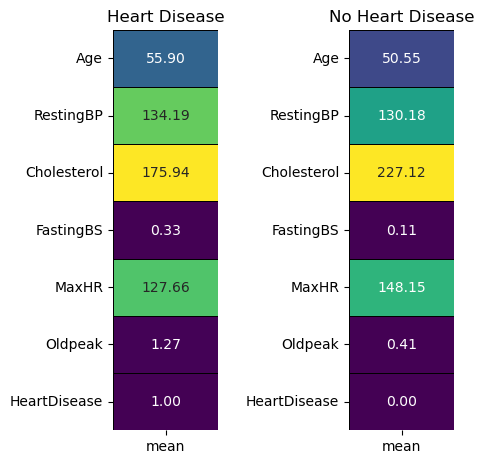

In [6]:
yes = df[df["HeartDisease"] == 1].describe().T
no = df[df["HeartDisease"] == 0].describe().T
def plot_heatmap(var): 
    fig , ax = plt.subplots(nrows = 1,ncols = 2,figsize = (5,5))
    plt.subplot(1,2,1)
    try:
        sns.heatmap(yes[[str(var)]],annot = True,cmap = 'viridis',linewidths = 0.4,linecolor = 'black',cbar = False,fmt = '.2f',)
    except KeyError:
        return f"{var} not found!"
    plt.title('Heart Disease');

    plt.subplot(1,2,2)
    sns.heatmap(no[[str(var)]],annot = True,cmap = 'viridis',linewidths = 0.4,linecolor = 'black',cbar = False,fmt = '.2f')
    plt.title('No Heart Disease');

    fig.tight_layout(pad = 2)
    
plot_heatmap("mean")

In [7]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


#### With unfo methode we know now we didnt had null value cuese all the value nuber is 918

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [9]:
df.select_dtypes(include='object')

,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
0,M,ATA,Normal,N,Up
1,F,NAP,Normal,N,Flat
2,M,ATA,ST,N,Up
3,F,ASY,Normal,Y,Flat
4,M,NAP,Normal,N,Up
...,...,...,...,...,...
913,M,TA,Normal,N,Flat
914,M,ASY,Normal,N,Flat
915,M,ASY,Normal,Y,Flat
916,F,ATA,LVH,N,Flat



# The Attributess include:

*    Age: age of the patient [years]
*    Sex: sex of the patient [M: Male, F: Female]
*   ChestPainType: chest pain type [TA: Typical Angina, ATA: Atypical Angina, NAP: Non-Anginal Pain, ASY:     Asymptomatic]
*   RestingBP: resting blood pressure [mm Hg]
*   Cholesterol: serum cholesterol [mm/dl]
*   FastingBS: fasting blood sugar [1: if FastingBS > 120 mg/dl, 0: otherwise]
*   RestingECG: resting electrocardiogram results [Normal: Normal, ST: having ST-T wave abnormality (T       wave inversions and/or ST elevation or depression of > 0.05 mV), LVH: showing probable or definite       left ventricular hypertrophy by Estes' criteria]
*   MaxHR: maximum heart rate achieved [Numeric value between 60 and 202]
*   ExerciseAngina: exercise-induced angina [Y: Yes, N: No]
*   Oldpeak: oldpeak = ST [Numeric value measured in depression]
*   ST_Slope: the slope of the peak exercise ST segment [Up: upsloping, Flat: flat, Down: downsloping]
*   HeartDisease: output class [1: heart disease, 0: Normal]



# <h1 style="font-family: Trebuchet MS; padding: 20px; font-size: 25px; color: #F93822; text-align: center; line-height: 0.75;background-color: #ADD8E6"><b>Categorical Features </b><br></h1>

In [10]:
df1 = df.copy(deep = True)

### For handle Categorical Features we can use sklearn Label Encoder

In [11]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df1 = df.copy(deep = True)

df1['Sex'] = le.fit_transform(df1['Sex'])
df1['ChestPainType'] = le.fit_transform(df1['ChestPainType'])
df1['RestingECG'] = le.fit_transform(df1['RestingECG'])
df1['ExerciseAngina'] = le.fit_transform(df1['ExerciseAngina'])
df1['ST_Slope'] = le.fit_transform(df1['ST_Slope'])

In [12]:
lst = ["Age" , "RestingBP" ,"Cholesterol" ,"FastingBS", "MaxHR" ]

In [13]:
string_col = df1.select_dtypes(include="Float64").columns
df1[string_col]=df1[string_col].astype("int64")

In [14]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Age             918 non-null    int64
 1   Sex             918 non-null    int64
 2   ChestPainType   918 non-null    int64
 3   RestingBP       918 non-null    int64
 4   Cholesterol     918 non-null    int64
 5   FastingBS       918 non-null    int64
 6   RestingECG      918 non-null    int64
 7   MaxHR           918 non-null    int64
 8   ExerciseAngina  918 non-null    int64
 9   Oldpeak         918 non-null    int64
 10  ST_Slope        918 non-null    int64
 11  HeartDisease    918 non-null    int64
dtypes: int64(12)
memory usage: 86.2 KB


/tmp/ipykernel_20/444022238.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df1[categorical_features[i]],kde_kws = {'bw' : 1},color = colors[0])
/opt/conda/lib/python3.10/site-packages/seaborn/distributions.py:2511: UserWarning: 

The `bw` parameter is deprecated in favor of `bw_method` and `bw_adjust`.
Setting `bw_method=1`, but please see the docs for the new parameters
and update your code. This will become an error in seaborn v0.13.0.

  kdeplot(**{axis: a}, ax=ax, color=kde_color, **kde_kws)
/tmp/ipykernel_20/444022238.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt you

Text(0.5, 1.0, 'Distribution : HeartDisease')

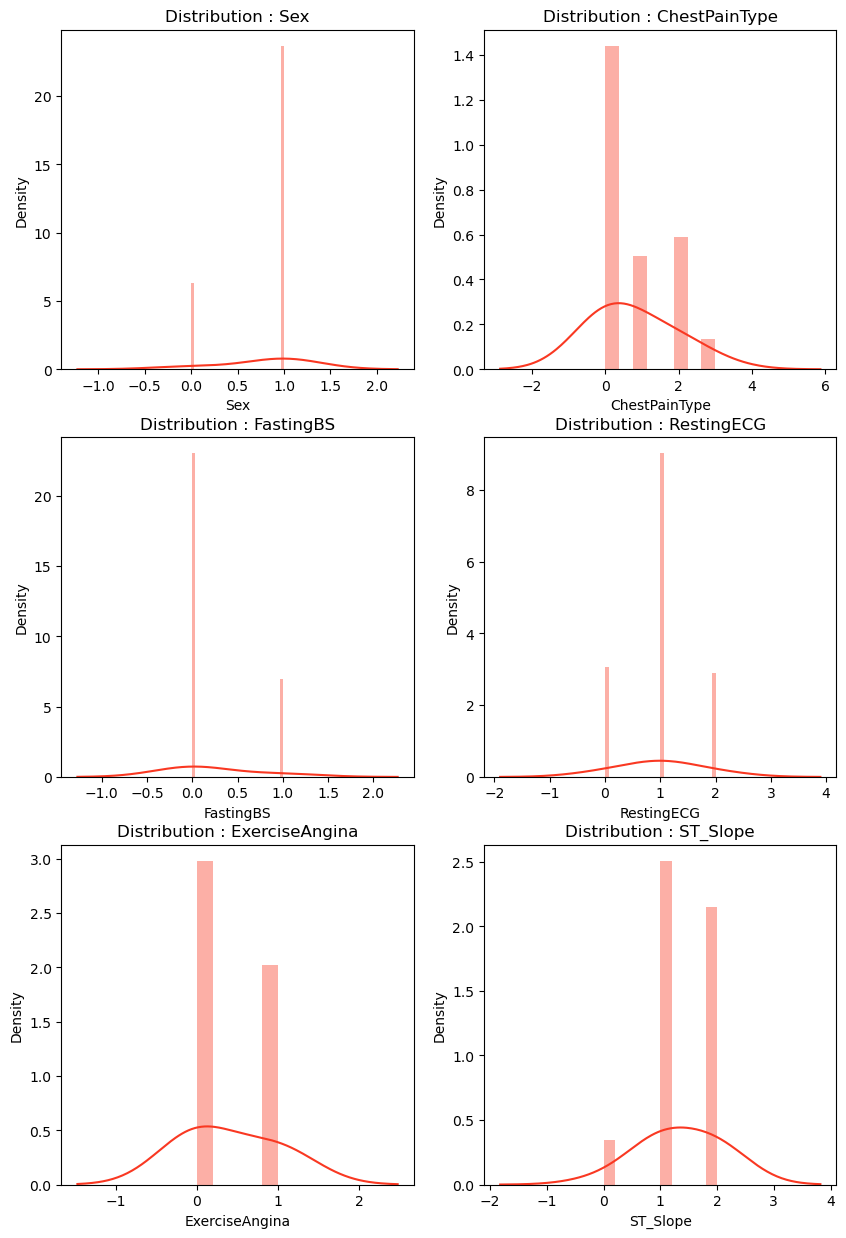

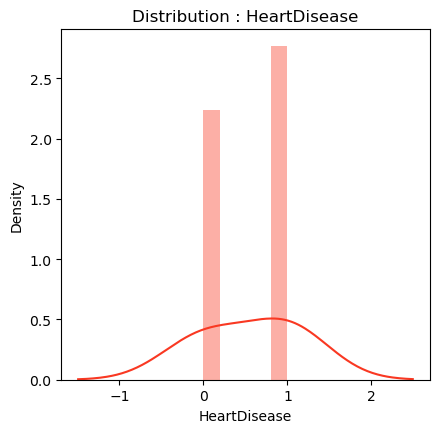

In [15]:
fig, ax = plt.subplots(nrows = 3,ncols = 2,figsize = (10,15))
colors = ['#F93822','#FDD20E']
for i in range(len(categorical_features) - 1):
    
    plt.subplot(3,2,i+1)
    sns.distplot(df1[categorical_features[i]],kde_kws = {'bw' : 1},color = colors[0])
    title = 'Distribution : ' + categorical_features[i]
    plt.title(title)
    
plt.figure(figsize = (4.75,4.55))
sns.distplot(df1[categorical_features[len(categorical_features) - 1]],kde_kws = {'bw' : 1},color = colors[0])
title = 'Distribution : ' + categorical_features[len(categorical_features) - 1]
plt.title(title)

In [16]:
X = df1.drop("HeartDisease" , axis=1)
Y = df1["HeartDisease"]

# <h1 style="font-family: Trebuchet MS; padding: 20px; font-size: 25px; color: #F93822; text-align: center; line-height: 0.75;background-color: #ADD8E6"><b>Features scaling</b><br></h1>

Feature scaling is a common preprocessing step in many machine learning algorithms, including logistic regression. It involves transforming the features so that they have similar scales or ranges. This can be beneficial for algorithms that are sensitive to the magnitude of features, as it can lead to faster convergence and better performance. Two common methods for feature scaling are Min-Max scaling and Standardization (Z-score scaling).

*     Min-Max Scaling:
    Min-Max scaling, also known as normalization, scales the features to a specific range, usually [0,       The formula for Min-Max scaling is as follows:
    # X_scaled = (X - X_min) / (X_max - X_min)
*   Standardization (Z-score Scaling):
    Standardization transforms the features to have a mean of 0 and a standard deviation of 1. The           formula for Standardization is as follows: 
    # X_scaled = (X - mean(X)) / std(X)

# <h1 style="font-family: Trebuchet MS; padding: 20px; font-size: 25px; color: #F93822; text-align: center; line-height: 0.75;background-color: #ADD8E6"><b>StandardScaler</b><br></h1> 

In [17]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# <h1 style="font-family: Trebuchet MS; padding: 20px; font-size: 25px; color: #F93822; text-align: center; line-height: 0.75;background-color: #ADD8E6"><b>Train Test validation</b><br></h1>

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, Y, test_size=0.2, random_state=42)

# <h1 style="font-family: Trebuchet MS; padding: 20px; font-size: 25px; color: #F93822; text-align: center; line-height: 0.75;background-color: #ADD8E6"><b>Logistic Regresion</b><br></h1>

In [19]:
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [20]:
y_pred = model.predict(X_test)

In [21]:
test_sizes = np.arange(0.1, 0.6, 0.1)


accuracy_scores = []
for test_size in test_sizes:

    X_train, X_test, y_train, y_test = train_test_split(X_scaled, Y, test_size=test_size, random_state=42)

    model = LogisticRegression()
    model.fit(X_train, y_train)


    y_pred = model.predict(X_test)


    accuracy = accuracy_score(y_test, y_pred)
    accuracy_scores.append(accuracy)




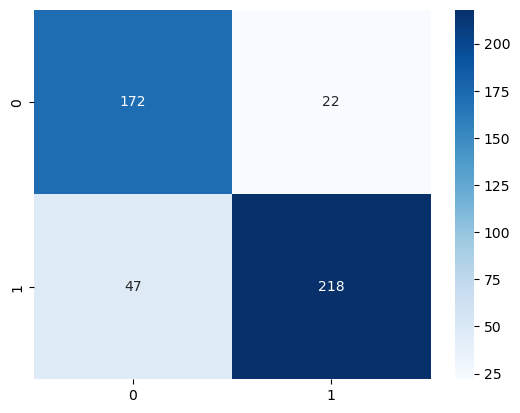

In [22]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='.0f', cmap='Blues')
plt.show()

# <h1 style="font-family: Trebuchet MS; padding: 20px; font-size: 25px; color: #F93822; text-align: center; line-height: 0.75;background-color: #ADD8E6"><b>Plot Accuracy</b><br></h1>

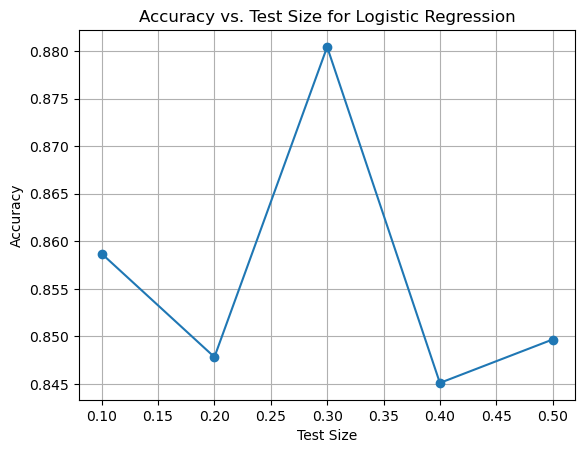

In [23]:
plt.plot(test_sizes, accuracy_scores, marker='o')
plt.xlabel('Test Size')
plt.ylabel('Accuracy')
plt.title('Accuracy vs. Test Size for Logistic Regression')
plt.grid(True)
plt.show()

# <h1 style="font-family: Trebuchet MS; padding: 20px; font-size: 25px; color: #F93822; text-align: center; line-height: 0.75;background-color: #ADD8E6"><b>SGDClassifier</b><br></h1>

In [24]:
from sklearn.linear_model import SGDClassifier

In [25]:
model = SGDClassifier()
model.fit(X_train, y_train)

SGDClassifier()

In [26]:
y_pred = model.predict(X_test)

In [27]:
test_sizes = np.arange(0.1, 0.6, 0.1)


accuracy_scores = []
for test_size in test_sizes:

    X_train, X_test, y_train, y_test = train_test_split(X_scaled, Y, test_size=test_size, random_state=42)

    model = SGDClassifier()
    model.fit(X_train, y_train)


    y_pred = model.predict(X_test)


    accuracy = accuracy_score(y_test, y_pred)
    accuracy_scores.append(accuracy)




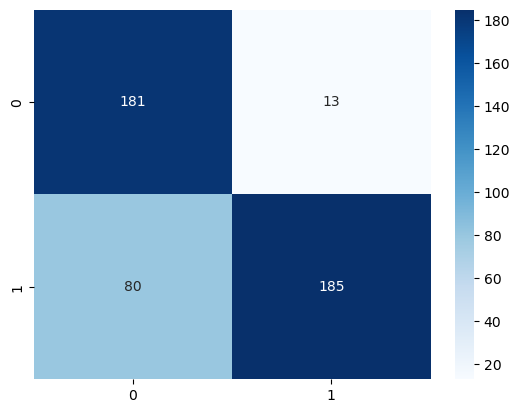

In [28]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='.0f', cmap='Blues')
plt.show()

# <h1 style="font-family: Trebuchet MS; padding: 20px; font-size: 25px; color: #F93822; text-align: center; line-height: 0.75;background-color: #ADD8E6"><b>Plot Accuracy</b><br></h1>

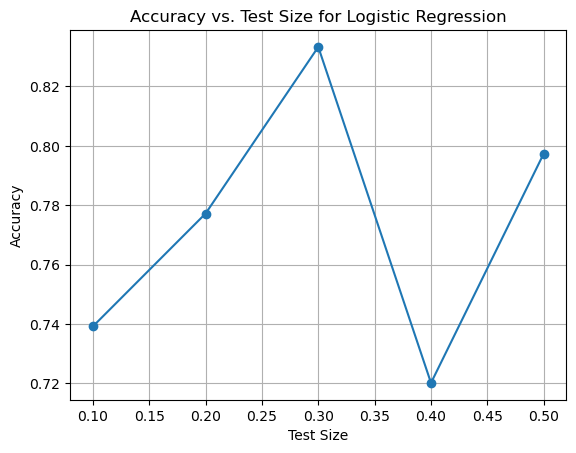

In [29]:
plt.plot(test_sizes, accuracy_scores, marker='o')
plt.xlabel('Test Size')
plt.ylabel('Accuracy')
plt.title('Accuracy vs. Test Size for Logistic Regression')
plt.grid(True)
plt.show()

# <h1 style="font-family: Trebuchet MS; padding: 20px; font-size: 25px; color: #F93822; text-align: center; line-height: 0.75;background-color: #ADD8E6"><b>Diffrent scaler methode</b><br></h1>

In [30]:
test_sizes = np.arange(0.1, 0.6, 0.1)
scalers = [StandardScaler(), MinMaxScaler(), MaxAbsScaler(), RobustScaler(), QuantileTransformer(), PowerTransformer(), FunctionTransformer()]
predictions = pd.DataFrame()

models = [LogisticRegression() , SGDClassifier()]
accuracy_scores = []
for test_size in test_sizes:
    X = df1.drop("HeartDisease" , axis=1)
    Y = df1["HeartDisease"]
    for scaler in scalers:
        X_scaled = scaler.fit_transform(X)

        X_train, X_test, y_train, y_test = train_test_split(X_scaled, Y, test_size=test_size, random_state=42)

        for model in models:
            
            model.fit(X_train, y_train)


            y_pred = model.predict(X_test)



            accuracy = accuracy_score(y_test, y_pred)
            accuracy_scores.append(accuracy)


            temp_data = pd.DataFrame({
            'test_size' : [test_size],
            'scaler'    : [scaler],
            'accuracy'  : [accuracy_score(y_test, y_pred)],
            'f1_score'  : [f1_score(y_test, y_pred)],
            "model"     : [model]
             })

            predictions = pd.concat([predictions, temp_data])

/opt/conda/lib/python3.10/site-packages/sklearn/preprocessing/_data.py:2627: UserWarning: n_quantiles (1000) is greater than the total number of samples (918). n_quantiles is set to n_samples.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/conda/lib/python3.10/site-packages/sklearn/preprocessing/_data.py:2627: UserWarning: n_quantiles (1000) is greater than the total number of samples (918). n_quantiles is set to n_samples.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_logisti

In [31]:
predictions

,test_size,scaler,accuracy,f1_score,model
0,0.1,StandardScaler(),0.858696,0.878505,LogisticRegression()
0,0.1,StandardScaler(),0.826087,0.846154,SGDClassifier()
0,0.1,MinMaxScaler(),0.858696,0.878505,LogisticRegression()
0,0.1,MinMaxScaler(),0.847826,0.870370,SGDClassifier()
0,0.1,MaxAbsScaler(),0.858696,0.878505,LogisticRegression()
...,...,...,...,...,...
0,0.5,QuantileTransformer(),0.873638,0.892989,SGDClassifier()
0,0.5,PowerTransformer(),0.860566,0.874510,LogisticRegression()
0,0.5,PowerTransformer(),0.832244,0.844444,SGDClassifier()
0,0.5,FunctionTransformer(),0.849673,0.863366,LogisticRegression()
